# FireBridge 3/3: Prediction
**Question:** for one MODIS detection, how many VIIRS detections would the same fire have produced?

If the model answers that well, we can convert the MODIS record from before 2012 onto the VIIRS scale.

**Input:** `FireBridge/data/processed/<country>_clean.parquet` from notebook 2  ·  **Output:** training pairs and predictions in `data/processed/`, models in `FireBridge/models/`

**Pipeline:** match MODIS and VIIRS → chronological split → compare 7 models → final test once → (optional) leave-one-country-out → apply to all MODIS → yearly totals check.

Builds on the team's first modeling notebook (*NASA_MODIS_VIIRS_Modeling_v1*): chronological split, MODIS-only features, Poisson-type models, honest test. The differences are explained at the matching step.

In [ ]:
!pip -q install duckdb xgboost
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Functions
Run once per session.  
Data: `loadClean`, `buildPairs`, `addFeatures`, `positives_only`, `blindSpot`, `splitByYear`.  
Models: `getModels` (average ratio, conditional mean, Poisson regression, random forest, HistGB, XGBoost, MLP with Poisson loss).  
Evaluation: `compareModels`, `finalTest`, `leaveOneCountryOut`.  
Apply: `predictAllMODIS`, `plotYearlyTotals`, `saveModel`.

The MLP uses a GPU automatically if the runtime has one. Everything else runs on CPU.

In [ ]:
import os, glob, json
import numpy as np
import pandas as pd
import duckdb
import joblib
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_poisson_deviance

PROCESSED_DIR = '/content/drive/MyDrive/FireBridge/data/processed'   # output of the preprocessing notebook
MODEL_DIR = '/content/drive/MyDrive/FireBridge/models'
RANDOM_STATE = 42

FEATURES = ['frp', 'scan', 'track', 'pixel_area', 'bright_fire', 'bright_bg', 'bright_diff',
            'confidence', 'is_day', 'month_sin', 'month_cos']
TARGET = 'viirs_count'


# ======================= data =======================
def loadClean(countries=None):
    """Lazy DuckDB table of cleaned detections (vegetation fires, both sensors) from the preprocessing notebook."""
    files = sorted(glob.glob(f'{PROCESSED_DIR}/*_clean.parquet'))
    if countries:
        wanted = {c.strip().replace(' ', '_').lower() for c in countries}
        files = [f for f in files if os.path.basename(f)[:-len('_clean.parquet')] in wanted]
    if not files:
        raise FileNotFoundError(f'No *_clean.parquet files in {PROCESSED_DIR} for {countries}. Run the preprocessing notebook first.')
    return duckdb.sql(f"SELECT * FROM read_parquet({files})")


def buildPairs(countries=None, max_minutes=50, margin_km=0.5, satellite='Aqua'):
    """One row per MODIS detection (Aqua by default) from the VIIRS era, with the target viirs_count.

    viirs_count = VIIRS detections within ±max_minutes that fall inside this MODIS pixel's footprint
                  (scan x track km box + margin_km), each VIIRS detection counted once, for its nearest MODIS pixel.
    Includes zeros (MODIS saw a fire, VIIRS saw nothing there in the same pass). Use positives_only() to drop them.
    """
    fires = loadClean(countries)
    sec = max_minutes * 60
    pairs = duckdb.sql(f"""
        WITH m AS (
            SELECT row_number() OVER () AS m_id, *, epoch(datetime) AS t,
                   CAST(floor(epoch(datetime) / 3600) AS BIGINT) AS hour_bucket
            FROM fires WHERE sensor = 'modis' AND satellite = '{satellite}' AND year >= 2012),
        v AS (
            SELECT row_number() OVER () AS v_id, latitude, longitude, frp, country, epoch(datetime) AS t,
                   CAST(floor(epoch(datetime) / 3600) AS BIGINT) AS hour_bucket
            FROM fires WHERE sensor = 'viirs'),
        mb AS (
            SELECT m_id, country, latitude, longitude, scan, track, t,
                   unnest([hour_bucket - 1, hour_bucket, hour_bucket + 1]) AS hb
            FROM m),
        cand AS (
            SELECT mb.m_id, v.v_id, v.frp, v.t - mb.t AS dt,
                   (v.longitude - mb.longitude) * 111.32 * cos(radians(mb.latitude)) AS dx,
                   (v.latitude  - mb.latitude)  * 111.32                              AS dy,
                   mb.scan, mb.track
            FROM mb JOIN v ON v.country = mb.country AND v.hour_bucket = mb.hb
            WHERE abs(v.t - mb.t) <= {sec}),
        inside AS (
            SELECT *, row_number() OVER (PARTITION BY v_id ORDER BY dx*dx + dy*dy) AS rank
            FROM cand WHERE abs(dx) <= scan / 2 + {margin_km} AND abs(dy) <= track / 2 + {margin_km}),
        counts AS (
            SELECT m_id, COUNT(*) AS viirs_count, SUM(frp) AS viirs_frp_sum,
                   median(abs(dt)) / 60 AS gap_minutes
            FROM inside WHERE rank = 1 GROUP BY m_id)
        SELECT m.* EXCLUDE (t, hour_bucket),
               COALESCE(c.viirs_count, 0)   AS viirs_count,
               COALESCE(c.viirs_frp_sum, 0) AS viirs_frp_sum,
               c.gap_minutes
        FROM m LEFT JOIN counts c USING (m_id)
        ORDER BY m.datetime""").df()
    pairs = addFeatures(pairs)
    print(f'{len(pairs):,} {satellite} MODIS detections · {(pairs[TARGET] > 0).mean():.0%} have ≥1 VIIRS match · '
          f'mean viirs_count {pairs[TARGET].mean():.2f}')
    return pairs


def addFeatures(df):
    """Model inputs computed from MODIS columns only (never from VIIRS)."""
    df = df.copy()
    df['pixel_area'] = df['scan'] * df['track']
    df['bright_diff'] = df['bright_fire'] - df['bright_bg']
    df['is_day'] = (df['daynight'] == 'D').astype(int)
    month = pd.to_datetime(df['datetime']).dt.month
    df['month'] = month
    df['month_sin'] = np.sin(2 * np.pi * month / 12)
    df['month_cos'] = np.cos(2 * np.pi * month / 12)
    return df


def positives_only(df):
    return df[df[TARGET] > 0].reset_index(drop=True)


def blindSpot(pairs, countries=None, max_minutes=50, satellite='Aqua'):
    """Per year: VIIRS detections during MODIS passes vs. how many of them a MODIS pixel caught.
    The rest (blind spot) is what a per-MODIS-row model can never recover."""
    fires = loadClean(countries)
    during = duckdb.sql(f"""
        WITH m AS (SELECT DISTINCT country, CAST(floor(epoch(datetime) / 60) AS BIGINT) AS minute
                   FROM fires WHERE sensor = 'modis' AND satellite = '{satellite}'),
             pm AS (SELECT DISTINCT country, minute + d AS minute FROM m, range(-{max_minutes}, {max_minutes} + 1) r(d)),
             v AS (SELECT country, year, CAST(floor(epoch(datetime) / 60) AS BIGINT) AS minute
                   FROM fires WHERE sensor = 'viirs')
        SELECT country, year, COUNT(*) AS viirs_during_passes FROM v JOIN pm USING (country, minute)
        GROUP BY ALL""").df()
    caught = pairs.groupby(['country', 'year'])[TARGET].sum().rename('caught_by_modis_pixels').reset_index()
    out = during.merge(caught, on=['country', 'year'], how='left').fillna(0).sort_values(['country', 'year'])
    out['blind_spot_%'] = (100 * (1 - out['caught_by_modis_pixels'] / out['viirs_during_passes'])).round(1)
    return out.reset_index(drop=True)


def splitByYear(df, train_until=2020, val_years=(2021,), test_from=2022):
    """Chronological split: no detections from the same day or fire can land in two sets."""
    train = df[df['year'] <= train_until]
    val = df[df['year'].isin(val_years)]
    test = df[df['year'] >= test_from]
    for name, d in [('train', train), ('val', val), ('test', test)]:
        print(f'{name:5s}: {len(d):6,} rows  {d["year"].min()}–{d["year"].max()}  mean target {d[TARGET].mean():.2f}')
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)


# ======================= models =======================
class ConditionalMeanBaseline(BaseEstimator, RegressorMixin):
    """Mean VIIRS count per MODIS FRP bin and day/night (teammate's baseline)."""
    def __init__(self, bins=(5, 15, 30, 60, 120, 300)):
        self.bins = bins
    def _key(self, X):
        b = pd.cut(X['frp'].fillna(0).clip(lower=0), [-np.inf, *self.bins, np.inf], labels=False).astype(int)
        return (b.astype(str) + '_' + X['is_day'].astype(int).astype(str)).to_numpy()
    def fit(self, X, y):
        self.fallback_ = float(np.mean(y))
        self.means_ = pd.Series(np.asarray(y, float)).groupby(self._key(X)).mean().to_dict()
        return self
    def predict(self, X):
        return np.array([self.means_.get(k, self.fallback_) for k in self._key(X)])


class TorchPoissonMLP(BaseEstimator, RegressorMixin):
    """Small MLP trained with Poisson loss (target is a count). Uses GPU if available, otherwise CPU.
    Early stopping on a 15% slice of the training data (the latest rows, so it stays chronological)."""
    def __init__(self, hidden=(64, 32), lr=1e-3, batch_size=512, max_epochs=300, patience=15, dropout=0.1):
        self.hidden, self.lr, self.batch_size = hidden, lr, batch_size
        self.max_epochs, self.patience, self.dropout = max_epochs, patience, dropout

    def fit(self, X, y):
        import torch, torch.nn as nn
        torch.manual_seed(RANDOM_STATE)
        self.device_ = 'cuda' if torch.cuda.is_available() else 'cpu'
        self.imputer_ = SimpleImputer(strategy='median').fit(X)
        self.scaler_ = StandardScaler().fit(self.imputer_.transform(X))
        Xs = self.scaler_.transform(self.imputer_.transform(X)).astype(np.float32)
        ys = np.asarray(y, np.float32)
        n_val = max(1, int(0.15 * len(Xs)))
        Xt, yt, Xv, yv = Xs[:-n_val], ys[:-n_val], Xs[-n_val:], ys[-n_val:]
        layers, d = [], Xs.shape[1]
        for h in self.hidden:
            layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(self.dropout)]; d = h
        layers += [nn.Linear(d, 1)]                      # outputs log(rate)
        self.net_ = nn.Sequential(*layers).to(self.device_)
        opt = torch.optim.Adam(self.net_.parameters(), lr=self.lr)
        loss_fn = nn.PoissonNLLLoss(log_input=True)
        T = lambda a: torch.tensor(a, device=self.device_)
        Xt_, yt_, Xv_, yv_ = T(Xt), T(yt), T(Xv), T(yv)
        best, best_state, wait = np.inf, None, 0
        self.history_ = []
        for epoch in range(self.max_epochs):
            self.net_.train()
            perm = torch.randperm(len(Xt_), device=self.device_)
            for i in range(0, len(perm), self.batch_size):
                idx = perm[i:i + self.batch_size]
                opt.zero_grad()
                loss = loss_fn(self.net_(Xt_[idx]).squeeze(1), yt_[idx])
                loss.backward(); opt.step()
            self.net_.eval()
            with torch.no_grad():
                v = loss_fn(self.net_(Xv_).squeeze(1), yv_).item()
            self.history_.append(v)
            if v < best - 1e-5:
                best, wait = v, 0
                best_state = {k: t.detach().clone() for k, t in self.net_.state_dict().items()}
            else:
                wait += 1
                if wait >= self.patience: break
        self.net_.load_state_dict(best_state)
        self.epochs_ = epoch + 1
        return self

    def predict(self, X):
        import torch
        Xs = self.scaler_.transform(self.imputer_.transform(X)).astype(np.float32)
        self.net_.eval()
        with torch.no_grad():
            return torch.exp(self.net_(torch.tensor(Xs, device=self.device_)).squeeze(1)).cpu().numpy()


def getModels():
    imp = lambda: SimpleImputer(strategy='median')
    models = {
        'Average ratio (global mean)': DummyRegressor(strategy='mean'),
        'Conditional mean (FRP bins × day/night)': ConditionalMeanBaseline(),
        'Poisson regression': make_pipeline(imp(), StandardScaler(), PoissonRegressor(alpha=1.0, max_iter=800)),
        'Random forest': make_pipeline(imp(), RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                                                                    n_jobs=-1, random_state=RANDOM_STATE)),
        'HistGB Poisson': make_pipeline(imp(), HistGradientBoostingRegressor(loss='poisson', max_iter=300,
                                        max_leaf_nodes=15, learning_rate=0.05, random_state=RANDOM_STATE)),
        'MLP (Poisson loss)': TorchPoissonMLP(),
    }
    try:
        from xgboost import XGBRegressor
        models['XGBoost Poisson'] = make_pipeline(imp(), XGBRegressor(
            objective='count:poisson', n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9,
            colsample_bytree=0.9, reg_lambda=2, random_state=RANDOM_STATE, n_jobs=4))
    except ImportError:
        print('xgboost not installed; skipping it.')
    return models


# ======================= evaluation =======================
def metrics(y, pred):
    y = np.asarray(y, float); pred = np.clip(np.asarray(pred, float), 1e-9, None)
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
            'Poisson deviance': mean_poisson_deviance(y, pred),
            'Total bias %': 100 * (pred.sum() / max(y.sum(), 1e-9) - 1)}


def monthlyWAPE(df, pred):
    """Error on monthly totals per country, which is what the calendar shows."""
    t = df[['country', 'datetime']].copy()
    t['y'], t['p'] = df[TARGET].values, pred
    m = t.groupby(['country', pd.to_datetime(t['datetime']).dt.to_period('M')])[['y', 'p']].sum()
    return 100 * (m['y'] - m['p']).abs().sum() / max(m['y'].sum(), 1e-9)


def compareModels(models, train, val, features=FEATURES):
    rows, fitted = [], {}
    for name, model in models.items():
        try:
            model.fit(train[features], train[TARGET])
            p = np.clip(model.predict(val[features]), 0, None)
            rows.append({'model': name, **metrics(val[TARGET], p), 'Monthly WAPE %': monthlyWAPE(val, p)})
            fitted[name] = model
        except Exception as e:
            print(f'Skipping {name}: {type(e).__name__}: {e}')
    res = pd.DataFrame(rows).sort_values('Poisson deviance').reset_index(drop=True)
    return res, fitted


def finalTest(model, train, val, test, features=FEATURES):
    """Refit the chosen model on train+val, evaluate once on the held-out test years."""
    m = clone(model).fit(pd.concat([train, val])[features], pd.concat([train, val])[TARGET])
    p = np.clip(m.predict(test[features]), 0, None)
    report = pd.DataFrame([{**metrics(test[TARGET], p), 'Monthly WAPE %': monthlyWAPE(test, p)}])
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].scatter(test[TARGET], p, s=8, alpha=0.4)
    lim = max(test[TARGET].max(), p.max(), 1); ax[0].plot([0, lim], [0, lim], '--', c='gray')
    ax[0].set(xlabel='actual VIIRS count', ylabel='predicted', title='Held-out test years')
    t = test[['datetime']].copy(); t['actual'] = test[TARGET].values; t['predicted'] = p
    t.groupby(pd.to_datetime(t['datetime']).dt.to_period('M'))[['actual', 'predicted']].sum().plot(ax=ax[1])
    ax[1].set(title='Monthly totals (test years)', ylabel='VIIRS detections')
    plt.tight_layout(); plt.show()
    return m, p, report


def leaveOneCountryOut(model, pairs, features=FEATURES):
    """Train on all other countries, test on the held-out one: does it generalize to a new place?"""
    rows = []
    for c in sorted(pairs['country'].unique()):
        tr, te = pairs[pairs.country != c], pairs[pairs.country == c]
        if len(tr) < 100 or len(te) < 50:
            print(f'Skipping {c}: not enough rows'); continue
        p = np.clip(clone(model).fit(tr[features], tr[TARGET]).predict(te[features]), 0, None)
        rows.append({'held_out': c, 'rows': len(te), **metrics(te[TARGET], p)})
    return pd.DataFrame(rows)


# ======================= apply / save =======================
def predictAllMODIS(model, countries=None, features=FEATURES):
    """Predicted VIIRS-equivalent count for every MODIS detection (2000 onward, Terra and Aqua).
    The model was trained on Aqua only: Terra predictions are an extrapolation (different overpass time)."""
    m = addFeatures(loadClean(countries).filter("sensor = 'modis'").df())
    m['predicted_viirs_count'] = np.clip(model.predict(m[features]), 0, None)
    return m


def plotYearlyTotals(modis_pred, countries=None):
    """Raw MODIS vs model-converted MODIS vs real VIIRS, per year. The 2012 join is the key check."""
    v = loadClean(countries).filter("sensor = 'viirs'").aggregate('country, year, count(*) AS viirs', 'country, year').df()
    for c in sorted(modis_pred['country'].unique()):
        mp = modis_pred[modis_pred.country == c]
        y = pd.DataFrame({'MODIS detections (raw)': mp.groupby('year').size(),
                          'MODIS → predicted VIIRS-equivalent': mp.groupby('year')['predicted_viirs_count'].sum()})
        y = y.join(v[v.country == c].set_index('year')['viirs'].rename('VIIRS detections (actual)'), how='outer')
        ax = y.plot(figsize=(12, 4), marker='o', logy=True, title=f'{c}: yearly totals')
        ax.axvline(2012, ls='--', c='gray'); ax.set_ylabel('detections (log scale)')
        plt.show()


def saveModel(model, name, info=None):
    os.makedirs(MODEL_DIR, exist_ok=True)
    path = f'{MODEL_DIR}/{name}.joblib'
    joblib.dump({'model': model, 'features': FEATURES, 'target': TARGET, **(info or {})}, path)
    print('Saved model →', path)
    return path

## 1. Build training pairs
One row per **Aqua** MODIS detection (2012 onward). Target `viirs_count` = VIIRS detections within **±50 min** that fall inside that MODIS pixel's own footprint (`scan × track` km + 0.5 km), each VIIRS detection counted once, for its nearest MODIS pixel.

**Why this differs from the v1 notebook:**
- *Unit:* v1 matched groups inside fixed 10 km grid cells. That predicts per grid cell, not per MODIS detection, and splits fires that sit on a cell border. Here each row is one MODIS detection, using its real pixel size.
- *Midnight:* v1 matched on the same UTC date. Night passes over Egypt are around 23:30 UTC, so many night pairs were split across two dates. Here matching uses the actual time gap.
- *Pass bins:* v1's fixed 30-minute bins could cut one pass in two. Not needed here.
- *Zeros:* v1 trained on positive pairs only. Here zeros are kept: VIIRS covers every location daily, and if MODIS saw the fire, the sky was clear within the same hour, so "VIIRS saw nothing" is usually a real observation. Both options are compared below.

In [ ]:
# Study regions preprocessed in notebook 2 (remove any you haven't run yet)
COUNTRIES = ['Egypt_Nile_Delta', 'Portugal_Centro', 'Guinea_Kankan_Siguiri', 'Canada_NWT_South',
             'Australia_NSW', 'Brazil_North_Pantanal', 'Indonesia_Central_Kalimantan']

pairs = buildPairs(COUNTRIES)
pairs.to_parquet(f'{PROCESSED_DIR}/overlap_pairs.parquet', index=False)
pairs[['country', 'datetime', 'frp', 'scan', 'track', 'daynight', 'viirs_count', 'gap_minutes']].head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

762,187 Aqua MODIS detections · 52% have ≥1 VIIRS match · mean viirs_count 1.92


,country,datetime,frp,scan,track,daynight,viirs_count,gap_minutes
0,Guinea_Kankan_Siguiri,2013-01-01 02:26:00,7.000000,1.1,1.0,N,1,29.0
1,Guinea_Kankan_Siguiri,2013-01-01 02:26:00,33.099998,1.1,1.0,N,2,29.0
2,Guinea_Kankan_Siguiri,2013-01-01 02:26:00,10.500000,1.0,1.0,N,2,29.0
3,Guinea_Kankan_Siguiri,2013-01-01 02:26:00,7.900000,1.1,1.0,N,3,29.0
4,Guinea_Kankan_Siguiri,2013-01-01 02:26:00,5.900000,1.1,1.0,N,0,NaN


### Blind spot
VIIRS detections during Aqua passes that **no MODIS pixel caught**. A per-MODIS-row model can never recover these, so converted totals will be too low by about this share. Keep this number for the pitch: it's the reason for version 2.

In [ ]:
blindSpot(pairs, COUNTRIES)

,country,year,viirs_during_passes,caught_by_modis_pixels,blind_spot_%
0,Australia_NSW,2013,71055,28502,59.9
1,Australia_NSW,2014,70165,27698,60.5
2,Australia_NSW,2015,43266,14400,66.7
3,Australia_NSW,2016,44227,15994,63.8
4,Australia_NSW,2017,67972,23866,64.9
...,...,...,...,...,...
79,Portugal_Centro,2020,1205,902,25.1
80,Portugal_Centro,2021,168,136,19.0
81,Portugal_Centro,2022,865,654,24.4
82,Portugal_Centro,2023,387,295,23.8


## 2. Choose the training rows and split by year
`TRAIN_ON = 'all'` keeps zeros (recommended), `'positives'` matches the v1 notebook.

The split is by year (train ≤ 2020, validation 2021, test ≥ 2022), never random: detections of the same fire must not end up in both train and test.

In [ ]:
TRAIN_ON = 'all'      # 'all' or 'positives'

data = pairs if TRAIN_ON == 'all' else positives_only(pairs)
train, val, test = splitByYear(data)

train: 534,059 rows  2013–2020  mean target 2.00
val  : 40,236 rows  2021–2021  mean target 1.37
test : 187,892 rows  2022–2024  mean target 1.81


## 3. Compare models on the validation year
- **Poisson deviance** is the main score (lower is better); it's the right loss for counts.
- **Total bias %**: are the totals too high or too low? This matters most for the calendar.
- **Monthly WAPE %**: error on monthly totals.
- The **average ratio** is the bar to beat.

In [ ]:
results, fitted = compareModels(getModels(), train, val)
results.round(3)

,model,MAE,RMSE,Poisson deviance,Total bias %,Monthly WAPE %
0,HistGB Poisson,1.504,2.146,2.520,8.480,10.613
1,XGBoost Poisson,1.518,2.153,2.537,10.500,12.852
2,MLP (Poisson loss),1.514,2.154,2.542,9.336,12.224
3,Random forest,1.524,2.189,2.600,10.169,11.464
4,Conditional mean (FRP bins × day/night),1.588,2.206,2.653,18.060,22.863
5,Poisson regression,1.620,2.198,2.682,22.187,27.999
6,Average ratio (global mean),1.809,2.367,3.084,46.026,59.846


## 4. Final test, once
The best model is refit on train + validation and scored **once** on the held-out test years. If the test is bad, that's the result: don't tune on it.

Chosen: HistGB Poisson


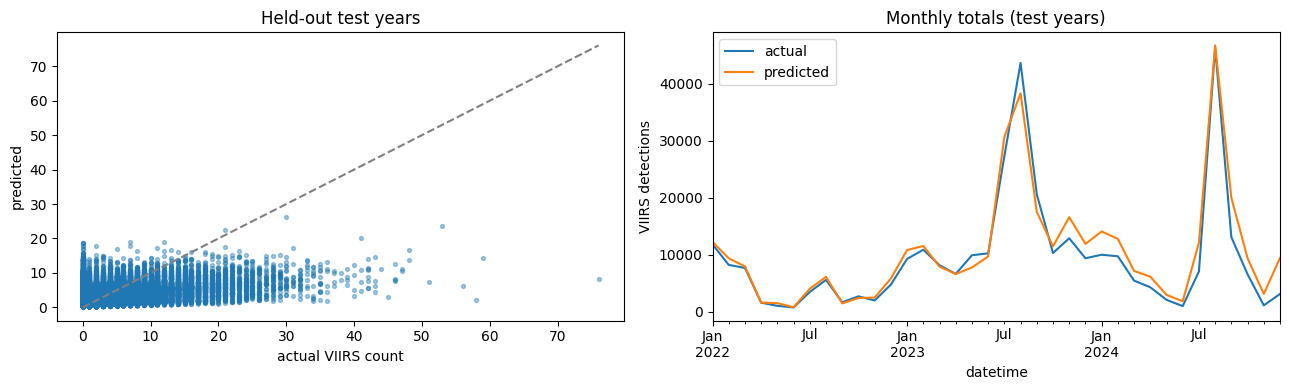

,MAE,RMSE,Poisson deviance,Total bias %,Monthly WAPE %
0,1.889,2.871,3.034,12.345,24.471


In [ ]:
BEST = results['model'].iloc[0]        # or pick by name, e.g. 'Poisson regression'
print('Chosen:', BEST)

best_model, test_pred, report = finalTest(fitted[BEST], train, val, test)
report.round(3)

In [ ]:
saveModel(best_model, 'modis_to_viirs_v1', {'chosen': BEST, 'train_on': TRAIN_ON, 'countries': COUNTRIES,
                                             'max_minutes': 50, 'margin_km': 0.5})

Saved model → /content/drive/MyDrive/FireBridge/models/modis_to_viirs_v1.joblib


'/content/drive/MyDrive/FireBridge/models/modis_to_viirs_v1.joblib'

## 5. Does it work in a new region?
Trains on all regions except one, tests on the one left out. With fire types this different (crop burning, boreal forest, peatland), this is the real test of whether the model learned sensor behaviour rather than one place.

In [ ]:
leaveOneCountryOut(fitted[BEST], pairs)

,held_out,rows,MAE,RMSE,Poisson deviance,Total bias %
0,Australia_NSW,196452,2.033112,3.307664,3.373299,-25.758386
1,Brazil_North_Pantanal,58596,2.387613,3.254685,3.649283,22.865989
2,Canada_NWT_South,73289,3.068223,4.732128,5.010803,-40.407231
3,Egypt_Nile_Delta,2469,0.962629,1.190733,1.682878,108.325390
4,Guinea_Kankan_Siguiri,328775,1.484959,2.002810,2.500122,24.427043
5,Indonesia_Central_Kalimantan,96669,1.732158,2.432342,2.717545,24.665046
6,Portugal_Centro,5937,2.822266,3.848072,3.999615,41.321263


## 6. Apply to every MODIS detection
Predicted VIIRS-equivalent count for every MODIS detection since 2000, Terra and Aqua.

**Caveats to state in the pitch:**
- The model is trained on **Aqua** only. Terra passes about 3 hours earlier, so Terra predictions are an extrapolation, and before mid-2002 only Terra exists.
- Because of the **blind spot**, converted totals stay far below real VIIRS totals. The chart shows the gap honestly.

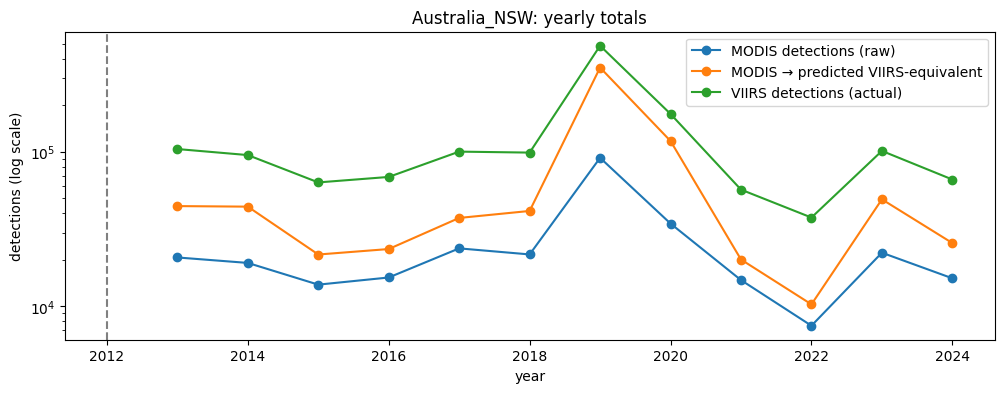

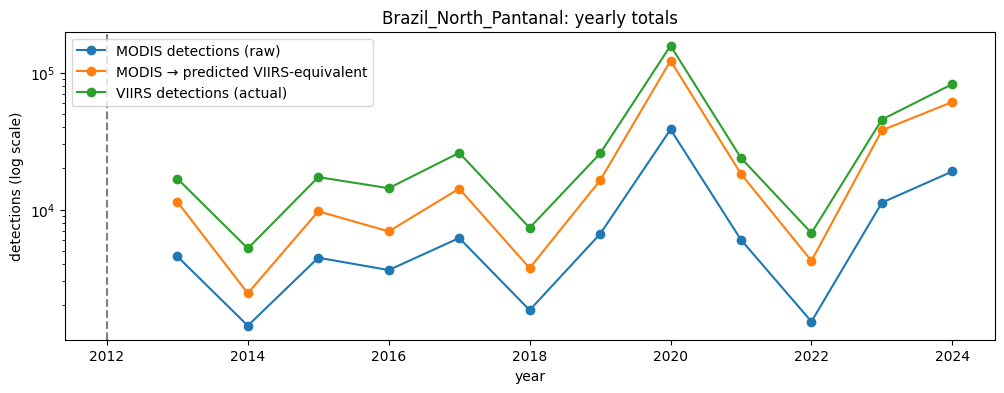

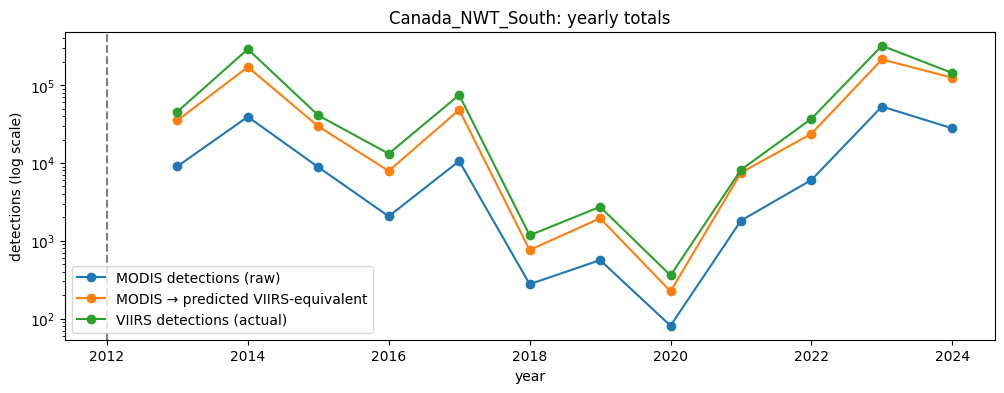

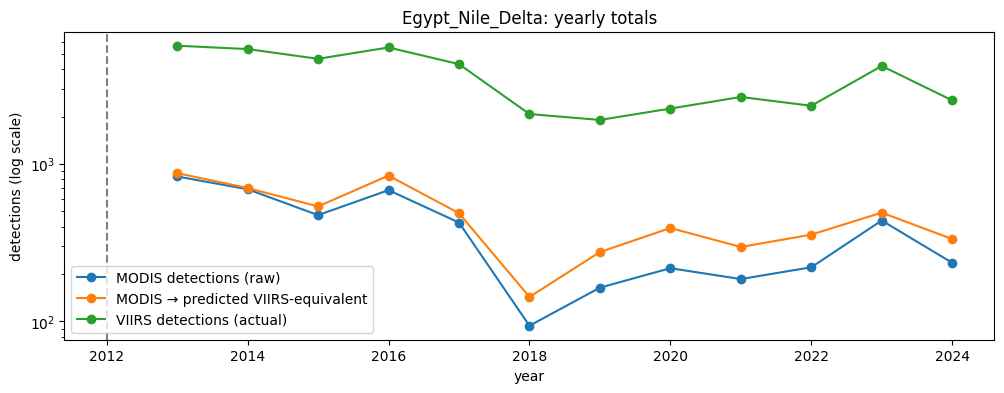

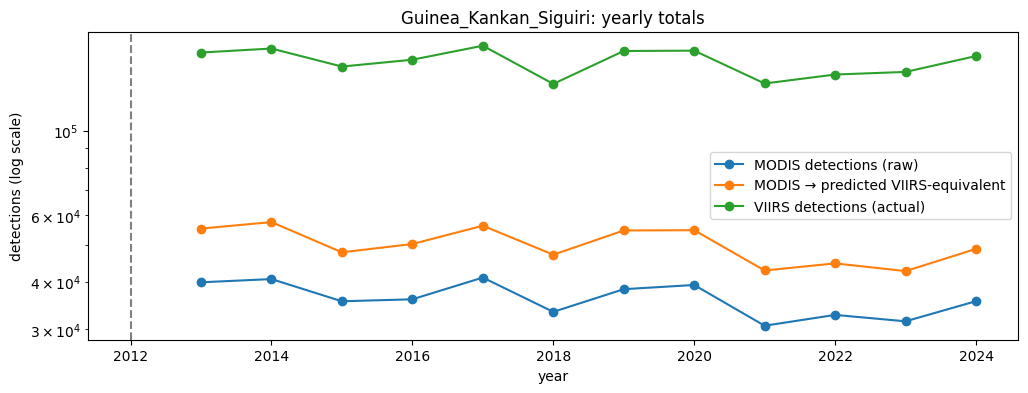

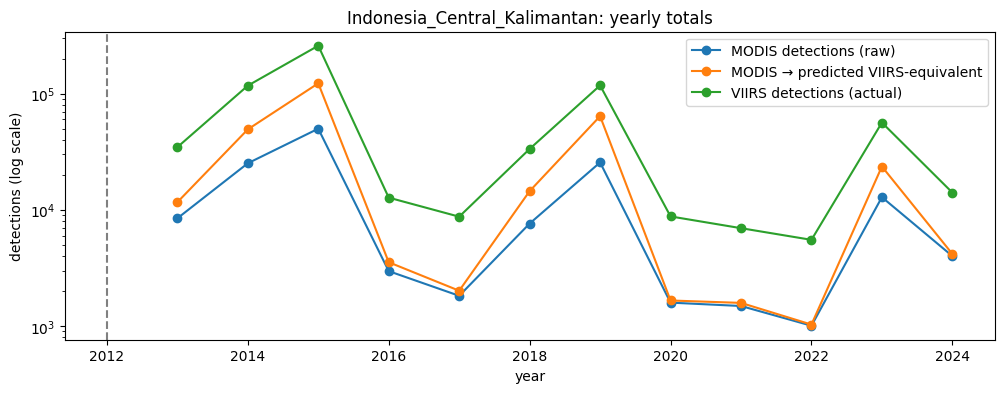

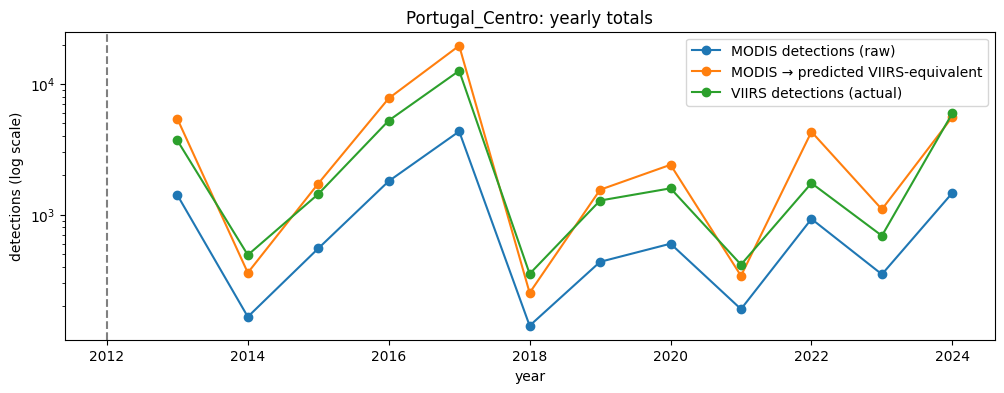

In [ ]:
modis_pred = predictAllMODIS(best_model, COUNTRIES)
modis_pred.to_parquet(f'{PROCESSED_DIR}/modis_predicted_viirs.parquet', index=False)
plotYearlyTotals(modis_pred, COUNTRIES)